# LHS/Sobol'-FMQAによるブラックボックス最適化

林 泰雅，関 優也

[T. Hayashi et al., "Improving FMQA via Initial Training Data Design Considering Marginal Bit Coverage in One-Hot Encoding" arXiv:2605.04825 (2026)](https://arxiv.org/abs/2605.04825)

## LHS/Sobol'-FMQAの概要

- LHS/Sobol'-FMQAは，ブラックボックス最適化手法であるfactorization machine with quadratic-optimization annealing（FMQA）\[1\] の**初期学習データ生成を改良**する手法である．
- Latin hypercube sampling（LHS）\[2\] またはSobol'準ランダム列 \[3\] を用いて**ビット網羅性の高いFMQAの初期学習データを生成**することで，FMQAの最適化性能を向上させる．

[1] [K. Kitai et al., Phys. Rev. Res., 2, 013319 (2020).](https://journals.aps.org/prresearch/abstract/10.1103/PhysRevResearch.2.013319)  
[2] [M. D. McKay et al., Technometrics 21, 239 (1979)](https://doi.org/10.2307/1268522)  
[3] [I. M. Sobol', USSR Comput. Math. Math. Phys., 7, 86 (1967)](https://doi.org/10.1016/0041-5553(67)90144-9)

## 背景

- FMQAでone-hotエンコーディングを用いた場合，入力データの多くの変数が0となる疎なデータセットを用いてFMの学習が行われる．
- 疎なデータセットでは，FMのモデルパラメータの勾配の大部分が消失してしまい，FMモデルの推定精度が低下する恐れがある．

パラメータ $\boldsymbol{\theta} \equiv (\omega_0, \{\omega_i\}_{i=1}^N, \{\boldsymbol{v}_i\}_{i=1}^N)$, $\boldsymbol{v}_i \in \mathbb{R}^K$ を持つFMのモデル方程式

$$
\begin{align}
f_{\mathrm{FM}}(\boldsymbol{x}; \boldsymbol{\theta}) = \omega_0 + \sum_{i=1}^N \omega_i x_i + \sum_{1 \le i < j \le N} \langle \boldsymbol{v}_i, \boldsymbol{v}_j \rangle x_i x_j.
\end{align}
$$

を考える．このモデル方程式に対する平均二乗誤差 $L(\boldsymbol{\theta})$ の勾配を計算すると

$$
\begin{align}
\frac{\partial L(\boldsymbol{\theta})}{\partial\theta} \propto \frac{\partial f_{\mathrm{FM}}(\boldsymbol{x}; \boldsymbol{\theta})}{\partial\theta} = \begin{cases}
1 & (\theta = w_0), \\
x_i & (\theta = w_i), \\
\left(\sum_{j=1}^{N}v_{j,l}x_{j}\right)x_i - v_{i,l}x_i^2 & (\theta=v_{i,l}),
\end{cases}
\end{align}
$$
となる．ここから，データセット内の全てのデータ点に対して $x_i=0$ となる場合，$w_i$ および $v_{i,l}$ $(l=1,\dotsc , K)$ が全て $0$ となってしまうことがわかる．

更新されないモデルパラメータがあることで，FMの推定精度が低下してしまう．下図は，全ての $i$ に対して $x_i = 1$ となるデータ点が少なくとも1つ含まれるように生成したデータセット（Proposed）と，ランダムに生成したデータセット (Convergence-Unaware) を用いて対象の関数を学習した結果である．

<div align="center">
  <img src="./illust/convergence_aware_sampling.png" width="550" alt="網羅性を考慮した初期サンプルによる初期推定精度の向上"> 
</div>

Convergence-unaware 手法では，全てのデータ点に対して $x_i = 0$ となる $i$ が存在してしまい，関数の推定精度も低くなっている．一方，Proposed 手法はより高い精度で対象の関数を近似できていることが確かめられる．このように，全ての $i$ に対して $x_i = 1$ となるデータ点を含むようにデータセットのビット網羅性を高めることで，FMの推定精度向上を目指す．

## 手法の目的

LHSやSobol'準ランダム列によりビット網羅性の高い初期学習データを生成することで，初期FMの推定精度の向上およびモデルパラメータの適切な更新を達成する．それにより，FMQAの最適化性能を向上させること．

## LHS/Sobol'-FMQAの手順

### 手法の主要パラメータ（抜粋）

* `n_init_data`: 初期学習データ数（Sobol'準ランダム列では2のべき乗を推奨）
* `sampling_method`: 初期データサンプル手法（`"lhs"`または`"sobol"`）
* `seed`: 初期サンプル生成のシード値

### アルゴリズムの手順

1. LHSまたはSobol'準ランダム列を用いて，各座標が$[0, 1)$上の連続値である点を生成する．
2. 各座標を対応する変数の定義域へ写像し，初期学習データ$x^{(d)}$を得る．離散化された実数変数では，$[0, 1)$を離散値の個数で等分した区間ごとに1つの離散値（one-hotベクトルの1つのビット）を割り当てる．
3. ブラックボックス関数の出力値$y^{(d)} = f_{\mathrm{BB}}(x^{(d)})$を得る．
4. 初期学習データセット$\mathcal{D}_0 = \{(x^{(d)}, y^{(d)})\}$を構築し，FMQAを実行する．

## ライブラリの使用方法

このライブラリでは，LHS/Sobol'-FMQAの実行に`amplify_bbopt`を使用する．

- `amplify_bbopt` のドキュメントは[こちら](https://amplify.fixstars.com/ja/docs/amplify-bbopt/v1/index.html)
- `amplify`のドキュメントは[こちら](https://amplify.fixstars.com/ja/docs/amplify/v1/index.html)

### 計算環境の準備

[Fixstars Amplify AEの利用方法](https://g-quat-abciq.github.io/abciq-docs/ja/apps/amplify-ae/)を参照して，必要ライブラリをインストールするための仮想環境を作成する．そして，仮想環境内に`amplify`と`amplify-bbopt`をインストールする．

```bash
python3 -m pip install -U amplify amplify-bbopt
```

また，`amplify-bbopt-ext`ライブラリを追加する．

```bash
python3 -m pip install git+https://github.com/Shu-Tanaka-Group/amplify-bbopt-ext.git
```

### 必要ライブラリの読み込み

In [8]:
import amplify_bbopt
from datetime import timedelta

import numpy as np
from amplify import FixstarsClient
from amplify_bbopt import DiscretizationSpec, EncodingMethod, RealVariable, blackbox
from amplify_bbopt_ext.utils import plot_optimization_history

from amplify_bbopt_ext.runner import run
from amplify_bbopt_ext.initial_sampling import QRS

In [2]:
amplify_bbopt.__version__

'1.0.3'

### パラメータ設定

本チュートリアルでは，実数変数のブラックボックス関数を対象とする．以下に，利用者が変更する主なパラメータを示す．

In [3]:
# ブラックボックス関数に関するパラメータ
n_variables = 2          # ブラックボックス関数の実数引数の個数
bounds = (-3.0, 3.0)     # 実数引数の上限と下限
n_bins = 32              # 実数の分割数（one-hotベクトルのビット数）

# 初期サンプリング手法に関するパラメータ
sampling_method = "lhs"  # "lhs" または "sobol"
n_init_data = 32
seed = 0

### ブラックボックス関数の設定

本チュートリアルでは，ブラックボックス関数のベンチマークとしてRastrigin関数を用いる．`RealVariable`には`EncodingMethod.OneHot`を指定し，各実数変数を`n_bins`個の離散値に離散化したうえでone-hotベクトルとしてFMQAに入力する．

In [4]:
disc_spec = DiscretizationSpec(num_bins=n_bins)
x_list = [
    RealVariable(bounds, encoding=EncodingMethod.OneHot, discretization_spec=disc_spec)
    for _ in range(n_variables)
]

def rastrigin(x: list[float] | np.ndarray) -> float:
    x_array = np.asarray(x, dtype=float)
    return float(
        10 * x_array.size
        + np.sum(x_array**2 - 10 * np.cos(2 * np.pi * x_array))
    )

@blackbox
def bb_func(input_x: list[float] = x_list) -> float:  # type: ignore
    return rastrigin(input_x)

### 初期サンプルの生成

In [5]:
initial_data = QRS.from_blackbox(sampling_method, bb_func, seed=seed).generate(n_init_data)

### FMQAの実行

`run`が内部で使用する`Optimizer`（amplify_bbopt標準）は初期学習データの入力値を内部でエンコーディングするため，本チュートリアル内でone-hotベクトルを構築する必要はない．

In [ ]:
client = FixstarsClient()

# Fixstars Amplify Engineのurlを設定（ABCI-Qの場合）
# client.url = "http://localhost:1080"
# トークンを指定（ABCI-Q以外の場合）
client.token = "YOUR_TOKEN_HERE"

client.parameters.timeout = timedelta(milliseconds=1000)
client.parameters.num_gpus = 1

result = run(
    client=client,
    bb_func=bb_func,
    n_iter=80,
    # 上で生成した初期データを渡す．
    initial_data=initial_data,
    num_factors=8,
    epochs=1000,
    optimizer_params={"lr": 0.01},
)
print(result.best.values)
print(result.best.objective)

## 結果の可視化

評価回数に対するブラックボックス関数の出力値と，それまでの最小値の推移を表示する．`result.training_data`および`result.history`から最適化プロセスの履歴を取得できる．

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'Optimization History'}, xlabel='Number of evaluations', ylabel='Objective value'>)

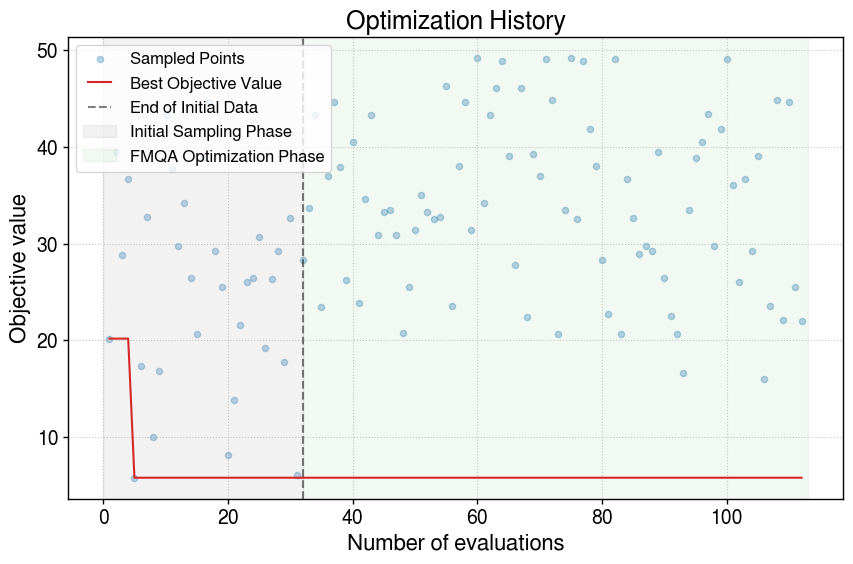

In [9]:
plot_optimization_history(result, n_init_data)

## パラメータ設定のTips

- 初期学習データ数 `n_init_data` を大きくすると各ビットの網羅性を満たしやすくなる一方で，ブラックボックス関数の呼び出し回数が増加する．
- Sobol'準ランダム列では任意の正の`n_init_data`を指定できるが，balance特性を保つため2のべき乗を推奨する．2のべき乗でない場合も処理は停止せず，警告を表示して指定された初期学習データ数が生成される．
- `QRS`の `scramble` は `True` （デフォルト値）を推奨． `False` にすると，Sobol準ランダム列の生成パターンが固定されてしまう．
- シード値 `seed` を固定することで初期学習データを再現できる．
- `QRS.from_blackbox`はブラックボックス関数の変数定義（`possible_values`）を読み取り，連続変数は定義域へスケーリングし，離散化された実数変数・整数変数・離散変数・バイナリ変数は候補値のいずれかを等しい割合で割り当てる．制約付き問題には対応していない．

## ビット網羅性の確認

ここでは，本手法が生成する初期学習データの分布（網羅性）を確認する．上述のチュートリアルと同じ設定で初期学習データを生成し，one-hotベクトルの各ビットが何回1になるか（ビット網羅性）を可視化する．

### 初期学習データの手動生成

初期学習データがどのように空間を埋めているかを確認するため，手動でサンプルを生成する．

In [ ]:
initial_data = QRS.from_blackbox(sampling_method, bb_func, seed=seed).generate(n_init_data)

### ブラックボックス関数の呼び出し

各初期学習データ$x^{(d)}$について，ブラックボックス関数の出力値$y^{(d)} = f(x^{(d)})$を取得する．

In [ ]:
initial_objectives = np.array([rastrigin(x) for x in initial_data])

### 各ビットの網羅性の確認

生成した初期学習データの各値を対応する離散値（＝one-hotベクトルのビット）に割り当て，各ビットが何回選ばれたかを可視化する．LHSでは`n_init_data`が`n_bins`の倍数のとき，Sobol'ではさらに`n_init_data`が2のべき乗のとき，全てのビットが同じ回数だけ選ばれる．

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# 各ビンのインデックスを計算（amplify_bboptのエンコーディングと同様に，最も近い離散値へ割り当てる）
discrete_indices = np.empty_like(initial_data, dtype=int)
for i, var in enumerate(x_list):
    discrete_values = np.asarray(var.possible_values)
    discrete_indices[:, i] = np.abs(initial_data[:, i, None] - discrete_values).argmin(axis=1)

# 各ビットの選ばれた回数をプロット
fig, axes = plt.subplots(
    1,
    n_variables,
    figsize=(4 * n_variables, 3),
    squeeze=False,
)
for index in range(n_variables):
    axes[0, index].hist(
        discrete_indices[:, index],
        bins=np.arange(n_bins + 1) - 0.5,
        rwidth=0.9,
    )
    axes[0, index].set_xlabel(f"Bin index for x{index + 1}")
    axes[0, index].set_ylabel("Count")
    axes[0, index].yaxis.set_major_locator(MaxNLocator(integer=True))
    
fig.suptitle("Initial Data Coverage", fontsize=14)
plt.tight_layout()
plt.show()

## LHS/Sobol'-FMQAの引用

```bibtex
@article{hayashi2026initialdata,
  title={Improving FMQA via Initial Training Data Design Considering Marginal Bit Coverage in One-Hot Encoding},
  author={Hayashi, Taiga and Seki, Yuya and Terada, Kotaro and Mukasa, Yosuke and Kikuchi, Shuta and Tanaka, Shu},
  journal={arXiv preprint arXiv:2605.04825},
  year={2026}
}
```